# EDA: xBD data exploration
Goal: understand what data we have, so the team can choose the subset for the project.

Questions this notebook answers:
1. What files do we have in each folder (`tier1`, `tier3`, `test`)?
2. How many images and buildings per event (the `disaster` name, like `hurricane-michael`) and per disaster type?
3. How are the damage classes balanced (overall, per split, per event, per disaster type)?
4. How big are the buildings, and how many buildings are in each image?
5. How different are the events from each other (sensor, camera angle, sun angle, dates, image colors)? This matters for domain adaptation.
6. Which events could be source and which could be target? (planner at the end)

**How to use**
- Keep this file in `notebooks/`. The data must be in `geotiffs/<split>/images` and `geotiffs/<split>/labels`.
- The first run reads every label JSON file, so it can take a few minutes. The result is saved in `cache/` (add `cache/` to `.gitignore`). Next runs load it quickly.
- Tables and figures are saved in `reports/eda/`, so we can reuse them in the report.
- Damage labels exist only in the **post-disaster** label files. All class counts here come from the post-disaster labels.

In [11]:
import json
import random
import re
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from IPython.display import display
import rasterio

try:
    from tqdm.auto import tqdm
except ImportError:                      # tqdm is optional
    def tqdm(x, **kwargs):
        return x

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
plt.rcParams["figure.dpi"] = 100

## 0. Settings
Change the values in this cell if needed.

In [12]:
# Paths are relative to the folder where this notebook is saved (notebooks/)
DATA_ROOT = Path("../geotiffs")
SPLITS = ["tier1", "tier3", "test"]        # add "hold" here if you want to include it
OUT_DIR = Path("../reports/eda")           # tables and figures (small files, can go to git)
CACHE_DIR = Path("../cache")               # big intermediate tables (do NOT put in git)
OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

REBUILD = False   # set True to read all JSON files again (needed if the data changed)
SEED = 42

# Damage classes. "un-classified" was found in the labels; any other name found is added automatically later.
CLASS_ORDER = ["no-damage", "minor-damage", "major-damage", "destroyed", "un-classified"]
DAMAGE4 = ["no-damage", "minor-damage", "major-damage", "destroyed"]
COLORS = {
    "no-damage": "lime",
    "minor-damage": "yellow",
    "major-damage": "orange",
    "destroyed": "red",
    "un-classified": "gray",
}

AVAILABLE_SPLITS = [s for s in SPLITS if (DATA_ROOT / s).exists()]
for s in SPLITS:
    if s not in AVAILABLE_SPLITS:
        print(f"WARNING: folder not found, skipped: {DATA_ROOT / s}")
print("Data folder  :", DATA_ROOT.resolve())
print("Splits used :", AVAILABLE_SPLITS)


def save_fig(name):
    plt.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

Data folder  : /Users/_nltdzdbh_/Desktop/Desktop-icloud/McGill/Fall2026/ECSE552/final_project/Satellite-Disaster-Assessment-with-Domain-Adaptation/geotiffs
Splits used : ['tier1', 'tier3', 'test']


## 1. File inventory
Check how many images and label files each folder has, and if every image has its pre/post pair and its label file.

In [13]:
NAME_RE = re.compile(r"^(?P<id>.+)_(?P<when>pre|post)_disaster$")


def split_name(stem):
    """'guatemala-volcano_00000000_post_disaster' -> ('guatemala-volcano_00000000', 'post')"""
    m = NAME_RE.match(stem)
    return (m["id"], m["when"]) if m else (stem, None)


rows = []
for split in AVAILABLE_SPLITS:
    img_dir = DATA_ROOT / split / "images"
    lab_dir = DATA_ROOT / split / "labels"
    tifs = list(img_dir.glob("*.tif")) if img_dir.exists() else []
    jsons = list(lab_dir.glob("*.json")) if lab_dir.exists() else []
    tif_pre = {split_name(p.stem)[0] for p in tifs if split_name(p.stem)[1] == "pre"}
    tif_post = {split_name(p.stem)[0] for p in tifs if split_name(p.stem)[1] == "post"}
    json_post = {split_name(p.stem)[0] for p in jsons if split_name(p.stem)[1] == "post"}
    rows.append({
        "split": split,
        "tif files": len(tifs),
        "json files": len(jsons),
        "pre images": len(tif_pre),
        "post images": len(tif_post),
        "pairs (pre+post)": len(tif_pre & tif_post),
        "post images without label": len(tif_post - json_post),
        "post labels without image": len(json_post - tif_post),
    })

inventory = pd.DataFrame(rows).set_index("split")
display(inventory)
print(f"Saving inventory.csv to {OUT_DIR}")
inventory.to_csv(OUT_DIR / "inventory.csv")

,tif files,json files,pre images,post images,pairs (pre+post),post images without label,post labels without image
split,,,,,,,
tier1,5598,5598,2799,2799,2799,0,0
tier3,12738,12738,6369,6369,6369,0,0
test,1866,1866,933,933,933,0,0


Saving inventory.csv to ../reports/eda


## 2. Read all labels into two tables
- **image table**: one row per image pair (event, split, sensor, angles, dates, number of buildings, ...)
- **building table**: one row per building in the post-disaster label (damage class, size in pixels, ...)

Building size is the polygon area in **pixels** (from the `xy` polygons), not in meters.

In [14]:
def parse_wkt_xy(wkt):
    """Outer ring of a POLYGON as an (N, 2) array. Returns None for other shapes."""
    if not wkt.startswith("POLYGON"):
        return None
    inner = wkt[wkt.index("((") + 2 : wkt.rindex("))")]
    ring = inner.split("),")[0]
    pts = np.array([[float(v) for v in p.split()] for p in ring.split(",")])
    return pts[:, :2]


def poly_area(pts):
    """Polygon area (shoelace formula)."""
    x, y = pts[:, 0], pts[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))


def read_json(path):
    with open(path) as f:
        return json.load(f)


def get_buildings(lab):
    return [b for b in lab.get("features", {}).get("xy", [])
            if b.get("properties", {}).get("feature_type", "building") == "building"]


def build_tables(splits):
    img_rows, bld_rows = [], []
    for split in splits:
        img_dir = DATA_ROOT / split / "images"
        lab_dir = DATA_ROOT / split / "labels"

        ids = set()
        for folder, pattern in ((img_dir, "*.tif"), (lab_dir, "*.json")):
            if folder.exists():
                ids |= {split_name(p.stem)[0] for p in folder.glob(pattern)}

        for image_id in tqdm(sorted(ids), desc=split):
            post_json = lab_dir / f"{image_id}_post_disaster.json"
            pre_json = lab_dir / f"{image_id}_pre_disaster.json"
            post = read_json(post_json) if post_json.exists() else None
            pre = read_json(pre_json) if pre_json.exists() else None

            row = {
                "split": split,
                "image_id": image_id,
                "disaster": image_id.rsplit("_", 1)[0],       # fallback: name from the file name
                "has_pre_tif": (img_dir / f"{image_id}_pre_disaster.tif").exists(),
                "has_post_tif": (img_dir / f"{image_id}_post_disaster.tif").exists(),
                "has_pre_json": pre is not None,
                "has_post_json": post is not None,
            }
            for tag, lab in (("pre", pre), ("post", post)):
                if lab is None:
                    continue
                meta = lab.get("metadata", {})
                row[f"capture_date_{tag}"] = meta.get("capture_date")
                row[f"off_nadir_{tag}"] = meta.get("off_nadir_angle")
                row[f"sun_elevation_{tag}"] = meta.get("sun_elevation")
                row[f"sun_azimuth_{tag}"] = meta.get("sun_azimuth")
                row[f"n_buildings_{tag}"] = len(get_buildings(lab))

            meta = (post or pre or {}).get("metadata", {})
            row["disaster"] = meta.get("disaster", row["disaster"])
            row["disaster_type"] = meta.get("disaster_type")
            row["sensor"] = meta.get("sensor")
            row["gsd"] = meta.get("gsd")
            row["width"] = meta.get("width")
            row["height"] = meta.get("height")
            img_rows.append(row)

            if post is not None:
                for b in get_buildings(post):
                    pts = parse_wkt_xy(b.get("wkt", ""))
                    bld_rows.append({
                        "split": split,
                        "image_id": image_id,
                        "disaster": row["disaster"],
                        "uid": b["properties"].get("uid"),
                        "subtype": b["properties"].get("subtype", "(no subtype)"),
                        "area_px": poly_area(pts) if pts is not None else np.nan,
                        "bbox_w": float(np.ptp(pts[:, 0])) if pts is not None else np.nan,
                        "bbox_h": float(np.ptp(pts[:, 1])) if pts is not None else np.nan,
                    })
    return pd.DataFrame(img_rows), pd.DataFrame(bld_rows)


IMG_CACHE = CACHE_DIR / "image_table.csv"
BLD_CACHE = CACHE_DIR / "building_table.csv.gz"

img = bld = None
if not REBUILD and IMG_CACHE.exists() and BLD_CACHE.exists():
    img, bld = pd.read_csv(IMG_CACHE), pd.read_csv(BLD_CACHE)
    if set(img["split"]) != set(AVAILABLE_SPLITS):
        print("The cache was made for other splits. Reading the files again...")
        img = bld = None
    else:
        print("Loaded tables from cache.")

if img is None:
    img, bld = build_tables(AVAILABLE_SPLITS)
    img.to_csv(IMG_CACHE, index=False)
    bld.to_csv(BLD_CACHE, index=False)
    print("Tables saved in", CACHE_DIR)

assert len(bld) > 0, "No building labels were found. Check DATA_ROOT and the labels folders."

# Clean-up
for tag in ("pre", "post"):
    if f"capture_date_{tag}" in img:
        img[f"capture_date_{tag}"] = pd.to_datetime(img[f"capture_date_{tag}"], errors="coerce", utc=True)
if {"capture_date_pre", "capture_date_post"} <= set(img.columns):
    img["gap_days"] = (img["capture_date_post"] - img["capture_date_pre"]).dt.days
img["disaster_type"] = img["disaster_type"].fillna("unknown")

# Class list: the known ones first, then any other name found in the data
CLASSES = CLASS_ORDER + sorted(set(bld["subtype"].unique()) - set(CLASS_ORDER))
bld["disaster_type"] = bld["disaster"].map(img.drop_duplicates("disaster").set_index("disaster")["disaster_type"])

print(f"{len(img):,} images, {len(bld):,} buildings, {img['disaster'].nunique()} events")
print("Damage labels found:", sorted(bld["subtype"].unique()))
img.head()

Loaded tables from cache.
10,101 images, 370,976 buildings, 19 events
Damage labels found: ['destroyed', 'major-damage', 'minor-damage', 'no-damage', 'un-classified']


,split,image_id,disaster,has_pre_tif,has_post_tif,has_pre_json,has_post_json,capture_date_pre,off_nadir_pre,sun_elevation_pre,sun_azimuth_pre,n_buildings_pre,capture_date_post,off_nadir_post,sun_elevation_post,sun_azimuth_post,n_buildings_post,disaster_type,sensor,gsd,width,height,gap_days
0,tier1,guatemala-volcano_00000000,guatemala-volcano,True,True,True,True,2018-02-05 17:10:18+00:00,17.933279,55.506645,150.80763,10,2018-06-22 16:55:40+00:00,21.97336,71.182274,58.571484,10,volcano,WORLDVIEW03_VNIR,1.408524,1024,1024,136
1,tier1,guatemala-volcano_00000001,guatemala-volcano,True,True,True,True,2018-02-05 17:10:18+00:00,17.933279,55.506645,150.80763,4,2018-06-22 16:55:40+00:00,21.97336,71.182274,58.571484,4,volcano,WORLDVIEW03_VNIR,1.408524,1024,1024,136
2,tier1,guatemala-volcano_00000002,guatemala-volcano,True,True,True,True,2018-02-05 17:10:18+00:00,17.933279,55.506645,150.80763,1,2018-06-22 16:55:40+00:00,21.97336,71.182274,58.571484,1,volcano,WORLDVIEW03_VNIR,1.408524,1024,1024,136
3,tier1,guatemala-volcano_00000006,guatemala-volcano,True,True,True,True,2018-02-05 17:10:18+00:00,17.933279,55.506645,150.80763,97,2018-06-22 16:55:40+00:00,21.97336,71.182274,58.571484,97,volcano,WORLDVIEW03_VNIR,1.408524,1024,1024,136
4,tier1,guatemala-volcano_00000007,guatemala-volcano,True,True,True,True,2018-02-05 17:10:18+00:00,17.933279,55.506645,150.80763,9,2018-06-22 16:55:40+00:00,21.97336,71.182274,58.571484,9,volcano,WORLDVIEW03_VNIR,1.408524,1024,1024,136


## 3. Images per event and per split
An **event** here is the `disaster` field (for example `hurricane-michael`). Each event has its own location and disaster type, so events are natural domains for domain adaptation.

split,disaster_type,tier1,tier3,test,total
disaster,,,,,
portugal-wildfire,fire,0,1869,0,1869
pinery-bushfire,fire,0,1845,0,1845
socal-fire,fire,823,0,307,1130
woolsey-fire,fire,0,878,0,878
nepal-flooding,flooding,0,619,0,619
hurricane-michael,wind,343,0,98,441
hurricane-harvey,flooding,319,0,108,427
hurricane-florence,flooding,319,0,108,427
midwest-flooding,flooding,279,0,80,359


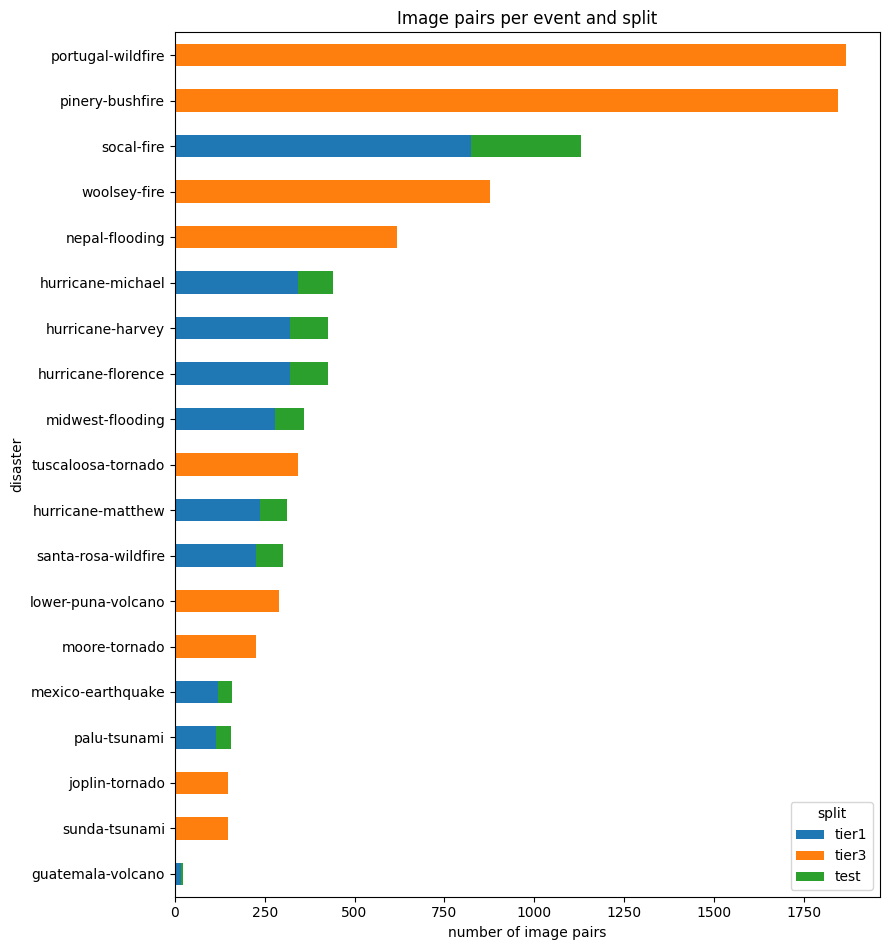

In [15]:
pv = img.pivot_table(index="disaster", columns="split", values="image_id", aggfunc="count", fill_value=0)
pv = pv.reindex(columns=AVAILABLE_SPLITS, fill_value=0)
pv["total"] = pv.sum(axis=1)
pv.insert(0, "disaster_type", img.drop_duplicates("disaster").set_index("disaster")["disaster_type"])
pv = pv.sort_values("total", ascending=False)
display(pv)

ax = pv[AVAILABLE_SPLITS].plot(kind="barh", stacked=True, figsize=(9, 0.4 * len(pv) + 2))
ax.invert_yaxis()
ax.set_xlabel("number of image pairs")
ax.set_title("Image pairs per event and split")
plt.tight_layout()
save_fig("images_per_event_split")
plt.show()

## 4. Disaster types

,events,images,buildings,event names
disaster_type,,,,
fire,5,6022,68312,"pinery-bushfire, portugal-wildfire, santa-rosa..."
flooding,4,1832,93996,"hurricane-florence, hurricane-harvey, midwest-..."
wind,5,1471,99787,"hurricane-matthew, hurricane-michael, joplin-t..."
volcano,2,314,4298,"guatemala-volcano, lower-puna-volcano"
tsunami,2,303,60901,"palu-tsunami, sunda-tsunami"
earthquake,1,159,43682,mexico-earthquake


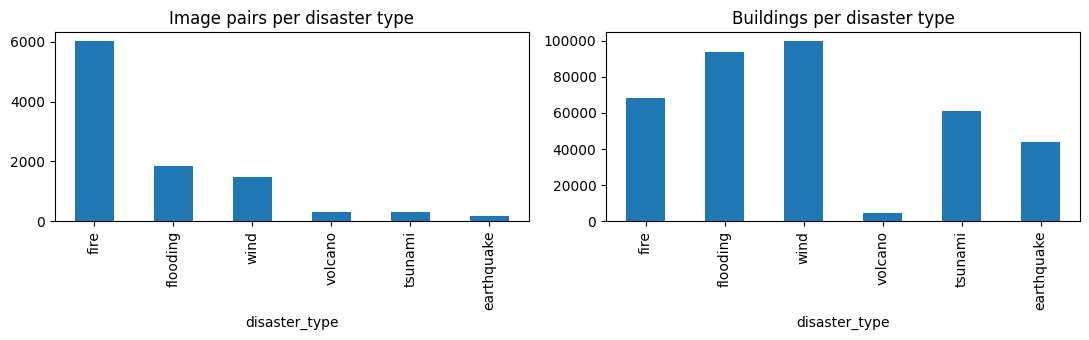

In [16]:
type_tbl = img.groupby("disaster_type").agg(events=("disaster", "nunique"), images=("image_id", "count"))
type_tbl["buildings"] = bld.groupby("disaster_type").size()
type_tbl["event names"] = img.groupby("disaster_type")["disaster"].apply(lambda s: ", ".join(sorted(s.unique())))
type_tbl = type_tbl.sort_values("images", ascending=False)
display(type_tbl)
type_tbl.to_csv(OUT_DIR / "disaster_types.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
type_tbl["images"].plot(kind="bar", ax=axes[0], title="Image pairs per disaster type")
type_tbl["buildings"].plot(kind="bar", ax=axes[1], title="Buildings per disaster type")
plt.tight_layout()
save_fig("disaster_types")
plt.show()

## 5. Buildings per event, and images without buildings

In [17]:
bld_per_split = pd.crosstab(bld["disaster"], bld["split"]).reindex(columns=AVAILABLE_SPLITS, fill_value=0)
bld_per_split["total buildings"] = bld_per_split.sum(axis=1)
bld_per_split = bld_per_split.sort_values("total buildings", ascending=False)
display(bld_per_split)

zero = img.assign(zero=img["n_buildings_post"].fillna(0).eq(0)).groupby("disaster").agg(
    images=("image_id", "count"), images_with_no_buildings=("zero", "sum"))
zero["% with no buildings"] = (100 * zero["images_with_no_buildings"] / zero["images"]).round(1)
display(zero.sort_values("% with no buildings", ascending=False))

print("Images with no building at all:", int(zero["images_with_no_buildings"].sum()), "of", len(img))

split,tier1,tier3,test,total buildings
disaster,,,,
palu-tsunami,31394,0,12560,43954
mexico-earthquake,32271,0,11411,43682
nepal-flooding,0,43265,0,43265
hurricane-harvey,23014,0,7715,30729
hurricane-michael,22686,0,5657,28343
portugal-wildfire,0,23413,0,23413
moore-tornado,0,22958,0,22958
hurricane-matthew,13939,0,4189,18128
santa-rosa-wildfire,12950,0,4226,17176


,images,images_with_no_buildings,% with no buildings
disaster,,,
pinery-bushfire,1845,1366,74.0
woolsey-fire,878,476,54.2
socal-fire,1130,563,49.8
portugal-wildfire,1869,894,47.8
lower-puna-volcano,291,108,37.1
sunda-tsunami,148,43,29.1
tuscaloosa-tornado,343,55,16.0
midwest-flooding,359,41,11.4
nepal-flooding,619,43,6.9


Images with no building at all: 3688 of 10101


## 6. Class balance (damage labels)
This is the most important part for choosing a subset. Accuracy alone can be misleading when one class is much bigger, so we will need macro-F1 and per-class recall (as in the proposal).

,buildings,%
subtype,,
no-damage,275062,74.15
minor-damage,30522,8.23
major-damage,25299,6.82
destroyed,27337,7.37
un-classified,12756,3.44


Imbalance ratio (biggest / smallest of the 4 damage classes): 10.9


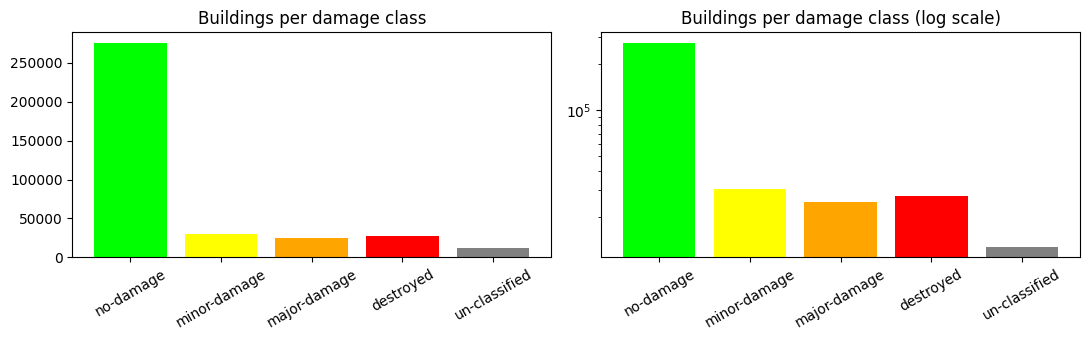

In [18]:
def class_table(df, by):
    ct = pd.crosstab(df[by], df["subtype"]).reindex(columns=CLASSES, fill_value=0)
    ct["total"] = ct.sum(axis=1)
    return ct


def pct_table(ct):
    return (ct[CLASSES].div(ct["total"], axis=0) * 100).round(1)


overall = bld["subtype"].value_counts().reindex(CLASSES, fill_value=0).to_frame("buildings")
overall["%"] = (100 * overall["buildings"] / overall["buildings"].sum()).round(2)
display(overall)

d4 = overall.loc[DAMAGE4, "buildings"]
if d4.min() > 0:
    print(f"Imbalance ratio (biggest / smallest of the 4 damage classes): {d4.max() / d4.min():.1f}")
else:
    print("At least one damage class has 0 buildings.")
overall.to_csv(OUT_DIR / "class_balance_overall.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, log in zip(axes, (False, True)):
    ax.bar(overall.index, overall["buildings"], color=[COLORS.get(c, "cyan") for c in overall.index])
    ax.set_yscale("log" if log else "linear")
    ax.set_title("Buildings per damage class" + (" (log scale)" if log else ""))
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
save_fig("class_balance_overall")
plt.show()

In [19]:
# Per split
ct_split = class_table(bld, "split")
display(ct_split)
display(pct_table(ct_split).add_suffix(" %"))
ct_split.to_csv(OUT_DIR / "class_balance_per_split.csv")

subtype,no-damage,minor-damage,major-damage,destroyed,un-classified,total
split,,,,,,
test,41427,4798,3850,3775,1012,54862
tier1,117426,14980,14161,13227,2993,162787
tier3,116209,10744,7288,10335,8751,153327


subtype,no-damage %,minor-damage %,major-damage %,destroyed %,un-classified %
split,,,,,
test,75.5,8.7,7.0,6.9,1.8
tier1,72.1,9.2,8.7,8.1,1.8
tier3,75.8,7.0,4.8,6.7,5.7


subtype,no-damage,minor-damage,major-damage,destroyed,un-classified,total
disaster,,,,,,
palu-tsunami,36382,1,821,6203,547,43954
mexico-earthquake,43350,194,49,3,86,43682
nepal-flooding,31225,5134,4721,502,1683,43265
hurricane-harvey,15591,3534,10612,597,395,30729
hurricane-michael,18235,6570,2311,940,287,28343
portugal-wildfire,20787,176,296,1090,1064,23413
moore-tornado,19453,886,449,1584,586,22958
hurricane-matthew,3132,8887,2281,2826,1002,18128
santa-rosa-wildfire,12507,97,72,4435,65,17176


subtype,no-damage %,minor-damage %,major-damage %,destroyed %,un-classified %
disaster,,,,,
palu-tsunami,82.8,0.0,1.9,14.1,1.2
mexico-earthquake,99.2,0.4,0.1,0.0,0.2
nepal-flooding,72.2,11.9,10.9,1.2,3.9
hurricane-harvey,50.7,11.5,34.5,1.9,1.3
hurricane-michael,64.3,23.2,8.2,3.3,1.0
portugal-wildfire,88.8,0.8,1.3,4.7,4.5
moore-tornado,84.7,3.9,2.0,6.9,2.6
hurricane-matthew,17.3,49.0,12.6,15.6,5.5
santa-rosa-wildfire,72.8,0.6,0.4,25.8,0.4


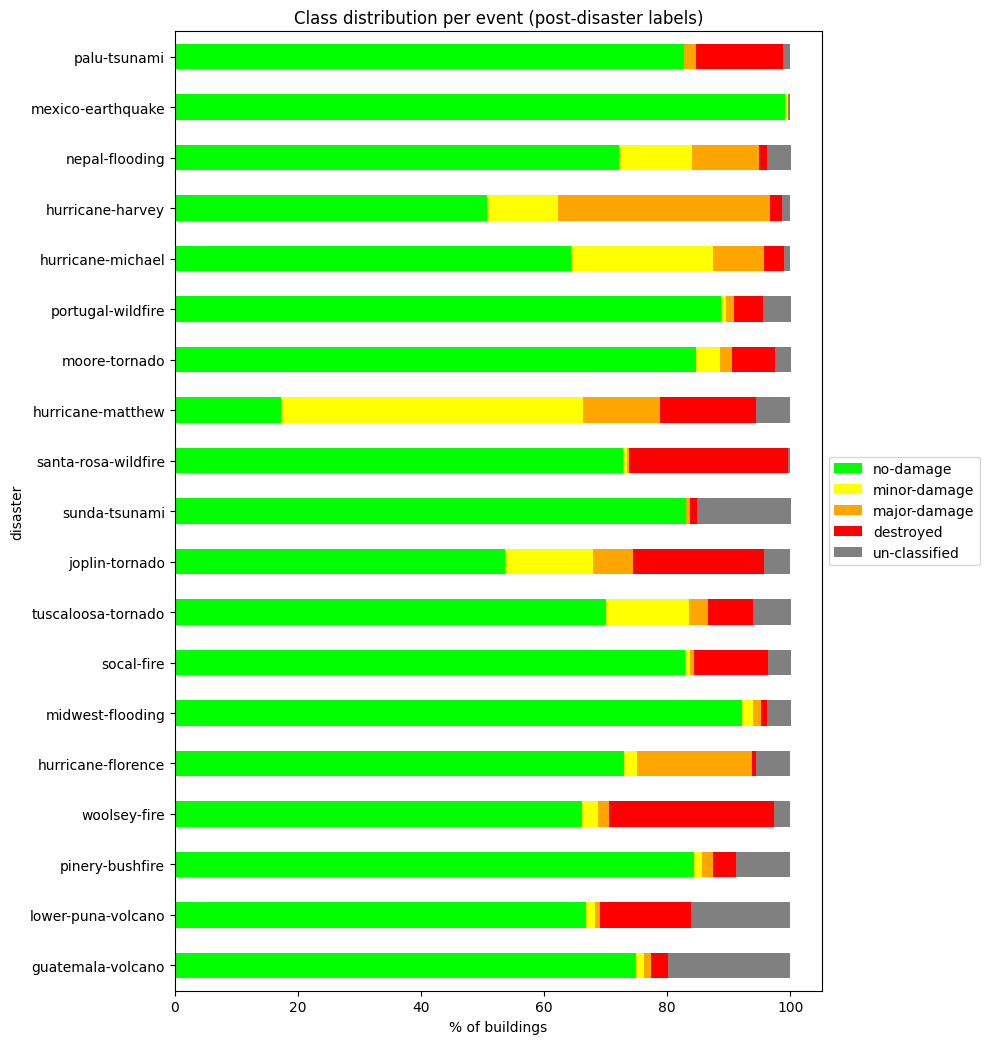

In [20]:
# Per event: counts and percentages
ct_event = class_table(bld, "disaster").sort_values("total", ascending=False)
pct_event = pct_table(ct_event)
display(ct_event)
display(pct_event.add_suffix(" %"))
ct_event.to_csv(OUT_DIR / "class_balance_per_event.csv")

ax = pct_event.plot(kind="barh", stacked=True, figsize=(10, 0.45 * len(pct_event) + 2),
                    color=[COLORS.get(c, "cyan") for c in pct_event.columns])
ax.invert_yaxis()
ax.set_xlabel("% of buildings")
ax.set_title("Class distribution per event (post-disaster labels)")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
save_fig("class_balance_per_event")
plt.show()

subtype,no-damage,minor-damage,major-damage,destroyed,un-classified,total
disaster_type,,,,,,
wind,59544,20571,6512,9721,3439,99787
flooding,63586,9040,17103,1286,2981,93996
fire,55180,655,679,9415,2383,68312
tsunami,50460,1,921,6382,3137,60901
earthquake,43350,194,49,3,86,43682
volcano,2942,61,35,530,730,4298


subtype,no-damage %,minor-damage %,major-damage %,destroyed %,un-classified %
disaster_type,,,,,
wind,59.7,20.6,6.5,9.7,3.4
flooding,67.6,9.6,18.2,1.4,3.2
fire,80.8,1.0,1.0,13.8,3.5
tsunami,82.9,0.0,1.5,10.5,5.2
earthquake,99.2,0.4,0.1,0.0,0.2
volcano,68.5,1.4,0.8,12.3,17.0


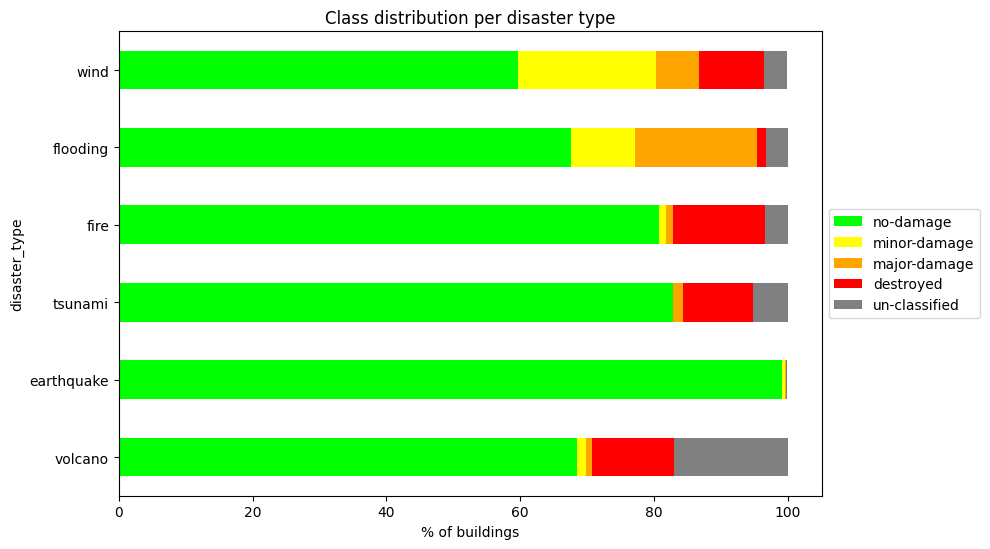

In [21]:
# Per disaster type
ct_type = class_table(bld, "disaster_type").sort_values("total", ascending=False)
display(ct_type)
display(pct_table(ct_type).add_suffix(" %"))
ct_type.to_csv(OUT_DIR / "class_balance_per_type.csv")

ax = pct_table(ct_type).plot(kind="barh", stacked=True, figsize=(10, 0.6 * len(ct_type) + 2),
                             color=[COLORS.get(c, "cyan") for c in CLASSES])
ax.invert_yaxis()
ax.set_xlabel("% of buildings")
ax.set_title("Class distribution per disaster type")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
save_fig("class_balance_per_type")
plt.show()

## 7. Building size and buildings per image

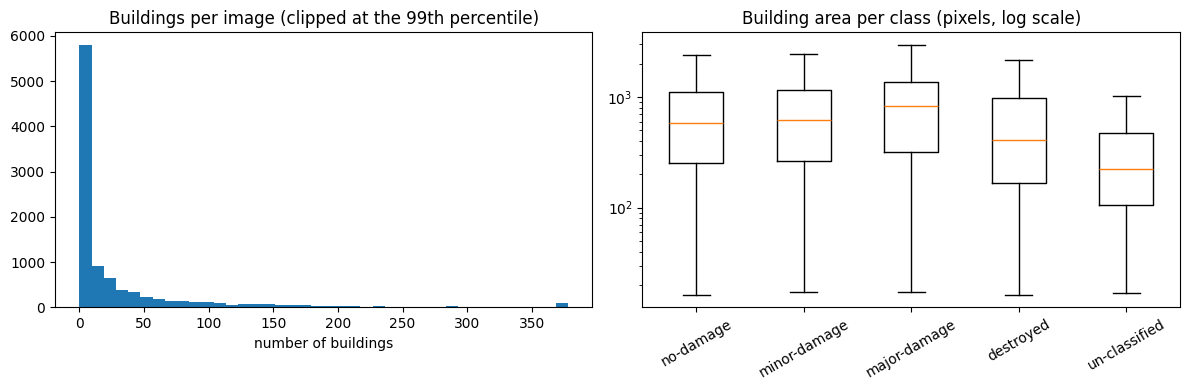

Buildings per image:


,count,mean,std,min,25%,50%,75%,max
buildings per image,10101.0,36.7,87.8,0.0,0.0,5.0,33.0,1843.0


,count,mean,25%,50%,75%,max
subtype,,,,,,
no-damage,275062.0,902.5,251.9,576.3,1106.7,398011.6
minor-damage,30522.0,911.1,265.6,619.7,1147.3,177335.2
major-damage,25299.0,1175.1,319.7,820.8,1375.4,118408.9
destroyed,27337.0,697.5,165.8,404.5,971.1,61654.0
un-classified,12756.0,411.7,105.9,222.9,470.8,72799.0


,median building area (px),buildings per image (median)
disaster,,
pinery-bushfire,225.2,0.0
hurricane-matthew,254.5,26.0
lower-puna-volcano,255.6,4.0
nepal-flooding,290.3,39.0
guatemala-volcano,323.7,12.0
sunda-tsunami,387.4,36.5
woolsey-fire,404.0,0.0
palu-tsunami,413.0,178.0
portugal-wildfire,427.4,1.0


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Buildings per image
n = img["n_buildings_post"].fillna(0)
axes[0].hist(n.clip(upper=n.quantile(0.99)), bins=40)
axes[0].set_title("Buildings per image (clipped at the 99th percentile)")
axes[0].set_xlabel("number of buildings")

# Building size per class
present = [c for c in CLASSES if (bld["subtype"] == c).any()]
data = [bld.loc[bld["subtype"] == c, "area_px"].dropna() for c in present]
axes[1].boxplot(data, showfliers=False)
axes[1].set_xticklabels(present, rotation=30)
axes[1].set_yscale("log")
axes[1].set_title("Building area per class (pixels, log scale)")
plt.tight_layout()
save_fig("building_counts_and_sizes")
plt.show()

print("Buildings per image:")
display(n.describe().round(1).to_frame("buildings per image").T)

size_by_class = bld.groupby("subtype")["area_px"].describe()[["count", "mean", "25%", "50%", "75%", "max"]].round(1)
display(size_by_class.reindex([c for c in CLASSES if c in size_by_class.index]))

size_by_event = bld.groupby("disaster")["area_px"].median().round(1).to_frame("median building area (px)")
size_by_event["buildings per image (median)"] = img.groupby("disaster")["n_buildings_post"].median()
display(size_by_event.sort_values("median building area (px)"))

## 8. Image metadata: how different are the events?
For domain adaptation, we want to know what changes between events: sensor, resolution (`gsd`), camera angle (`off_nadir`), sun elevation, dates, and the time gap between the pre and post images.

In [23]:
print("Image sizes (width x height):")
display(img.groupby(["width", "height"]).size().to_frame("images"))

if {"n_buildings_pre", "n_buildings_post"} <= set(img.columns):
    both = img.dropna(subset=["n_buildings_pre", "n_buildings_post"])
    same = (both["n_buildings_pre"] == both["n_buildings_post"]).mean() * 100
    print(f"Pairs where the pre and post labels have the same number of buildings: {same:.1f}% (of {len(both):,} pairs)")

ev_meta = img.groupby("disaster").agg(
    disaster_type=("disaster_type", "first"),
    images=("image_id", "count"),
    sensors=("sensor", lambda s: ", ".join(sorted(s.dropna().unique()))),
    gsd_median=("gsd", "median"),
    off_nadir_median=("off_nadir_post", "median"),
    sun_elevation_median=("sun_elevation_post", "median"),
    post_first=("capture_date_post", "min"),
    post_last=("capture_date_post", "max"),
    gap_days_median=("gap_days", "median"),
)
for c in ("post_first", "post_last"):
    ev_meta[c] = ev_meta[c].dt.date
display(ev_meta.round(2).sort_values("images", ascending=False))
ev_meta.to_csv(OUT_DIR / "event_metadata.csv")

Image sizes (width x height):


,,images
width,height,
1024,1024,10101


Pairs where the pre and post labels have the same number of buildings: 100.0% (of 10,101 pairs)


,disaster_type,images,sensors,gsd_median,off_nadir_median,sun_elevation_median,post_first,post_last,gap_days_median
disaster,,,,,,,,,
portugal-wildfire,fire,1869,WORLDVIEW02,2.23,25.35,71.46,2017-06-21,2017-06-21,333.0
pinery-bushfire,fire,1845,"WORLDVIEW02, WORLDVIEW03_VNIR",1.66,30.85,67.64,2015-11-27,2015-11-29,306.0
socal-fire,fire,1130,WORLDVIEW02,2.57,32.67,35.89,2018-11-14,2018-11-14,21.0
woolsey-fire,fire,878,GEOEYE01,1.77,16.21,34.94,2018-11-18,2018-11-18,25.0
nepal-flooding,flooding,619,GEOEYE01,2.34,34.13,66.97,2017-08-24,2017-08-24,120.0
hurricane-michael,wind,441,GEOEYE01,2.07,28.87,50.76,2018-10-13,2018-10-13,318.0
hurricane-harvey,flooding,427,GEOEYE01,3.02,42.91,66.45,2017-08-31,2017-08-31,196.0
hurricane-florence,flooding,427,GEOEYE01,2.09,28.02,53.72,2018-09-18,2018-09-20,167.0
midwest-flooding,flooding,359,"GEOEYE01, WORLDVIEW03_VNIR",1.25,7.11,72.40,2019-05-30,2019-05-31,124.0


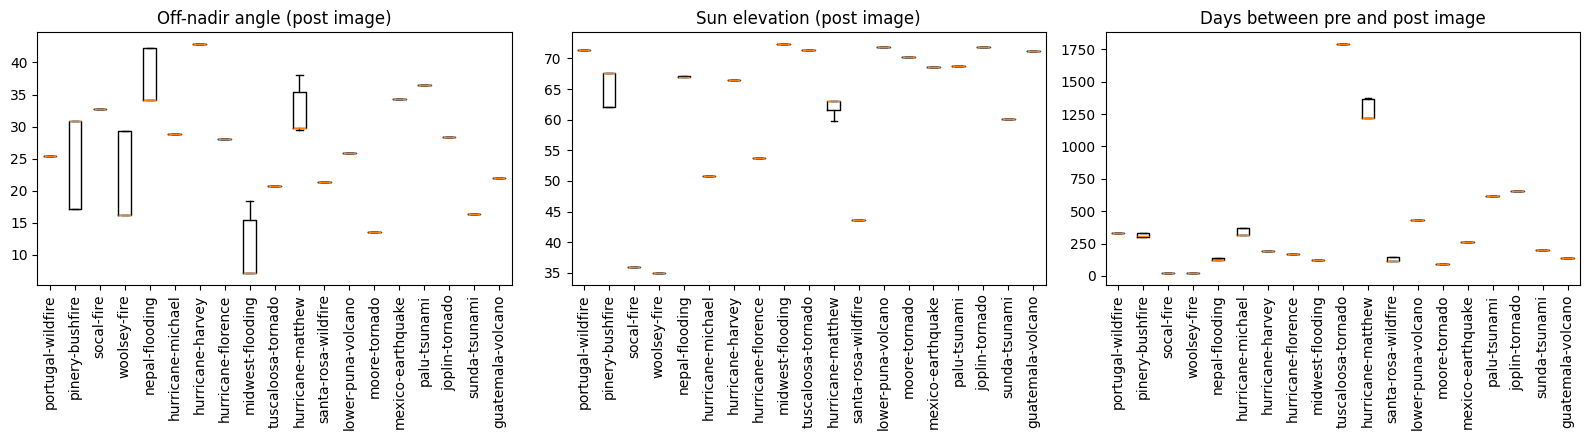

In [24]:
def box_by_event(ax, column, title):
    events = list(ev_meta.sort_values("images", ascending=False).index)
    data = [img.loc[img["disaster"] == e, column].dropna() for e in events]
    ax.boxplot(data, showfliers=False)
    ax.set_xticklabels(events, rotation=90)
    ax.set_title(title)


fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
box_by_event(axes[0], "off_nadir_post", "Off-nadir angle (post image)")
box_by_event(axes[1], "sun_elevation_post", "Sun elevation (post image)")
box_by_event(axes[2], "gap_days", "Days between pre and post image")
plt.tight_layout()
save_fig("metadata_per_event")
plt.show()

## 9. Sample images with building outlines (one per event)
Post-disaster image with the building outlines, colored by damage class. Run the cell again with another `SEED` to see other samples.

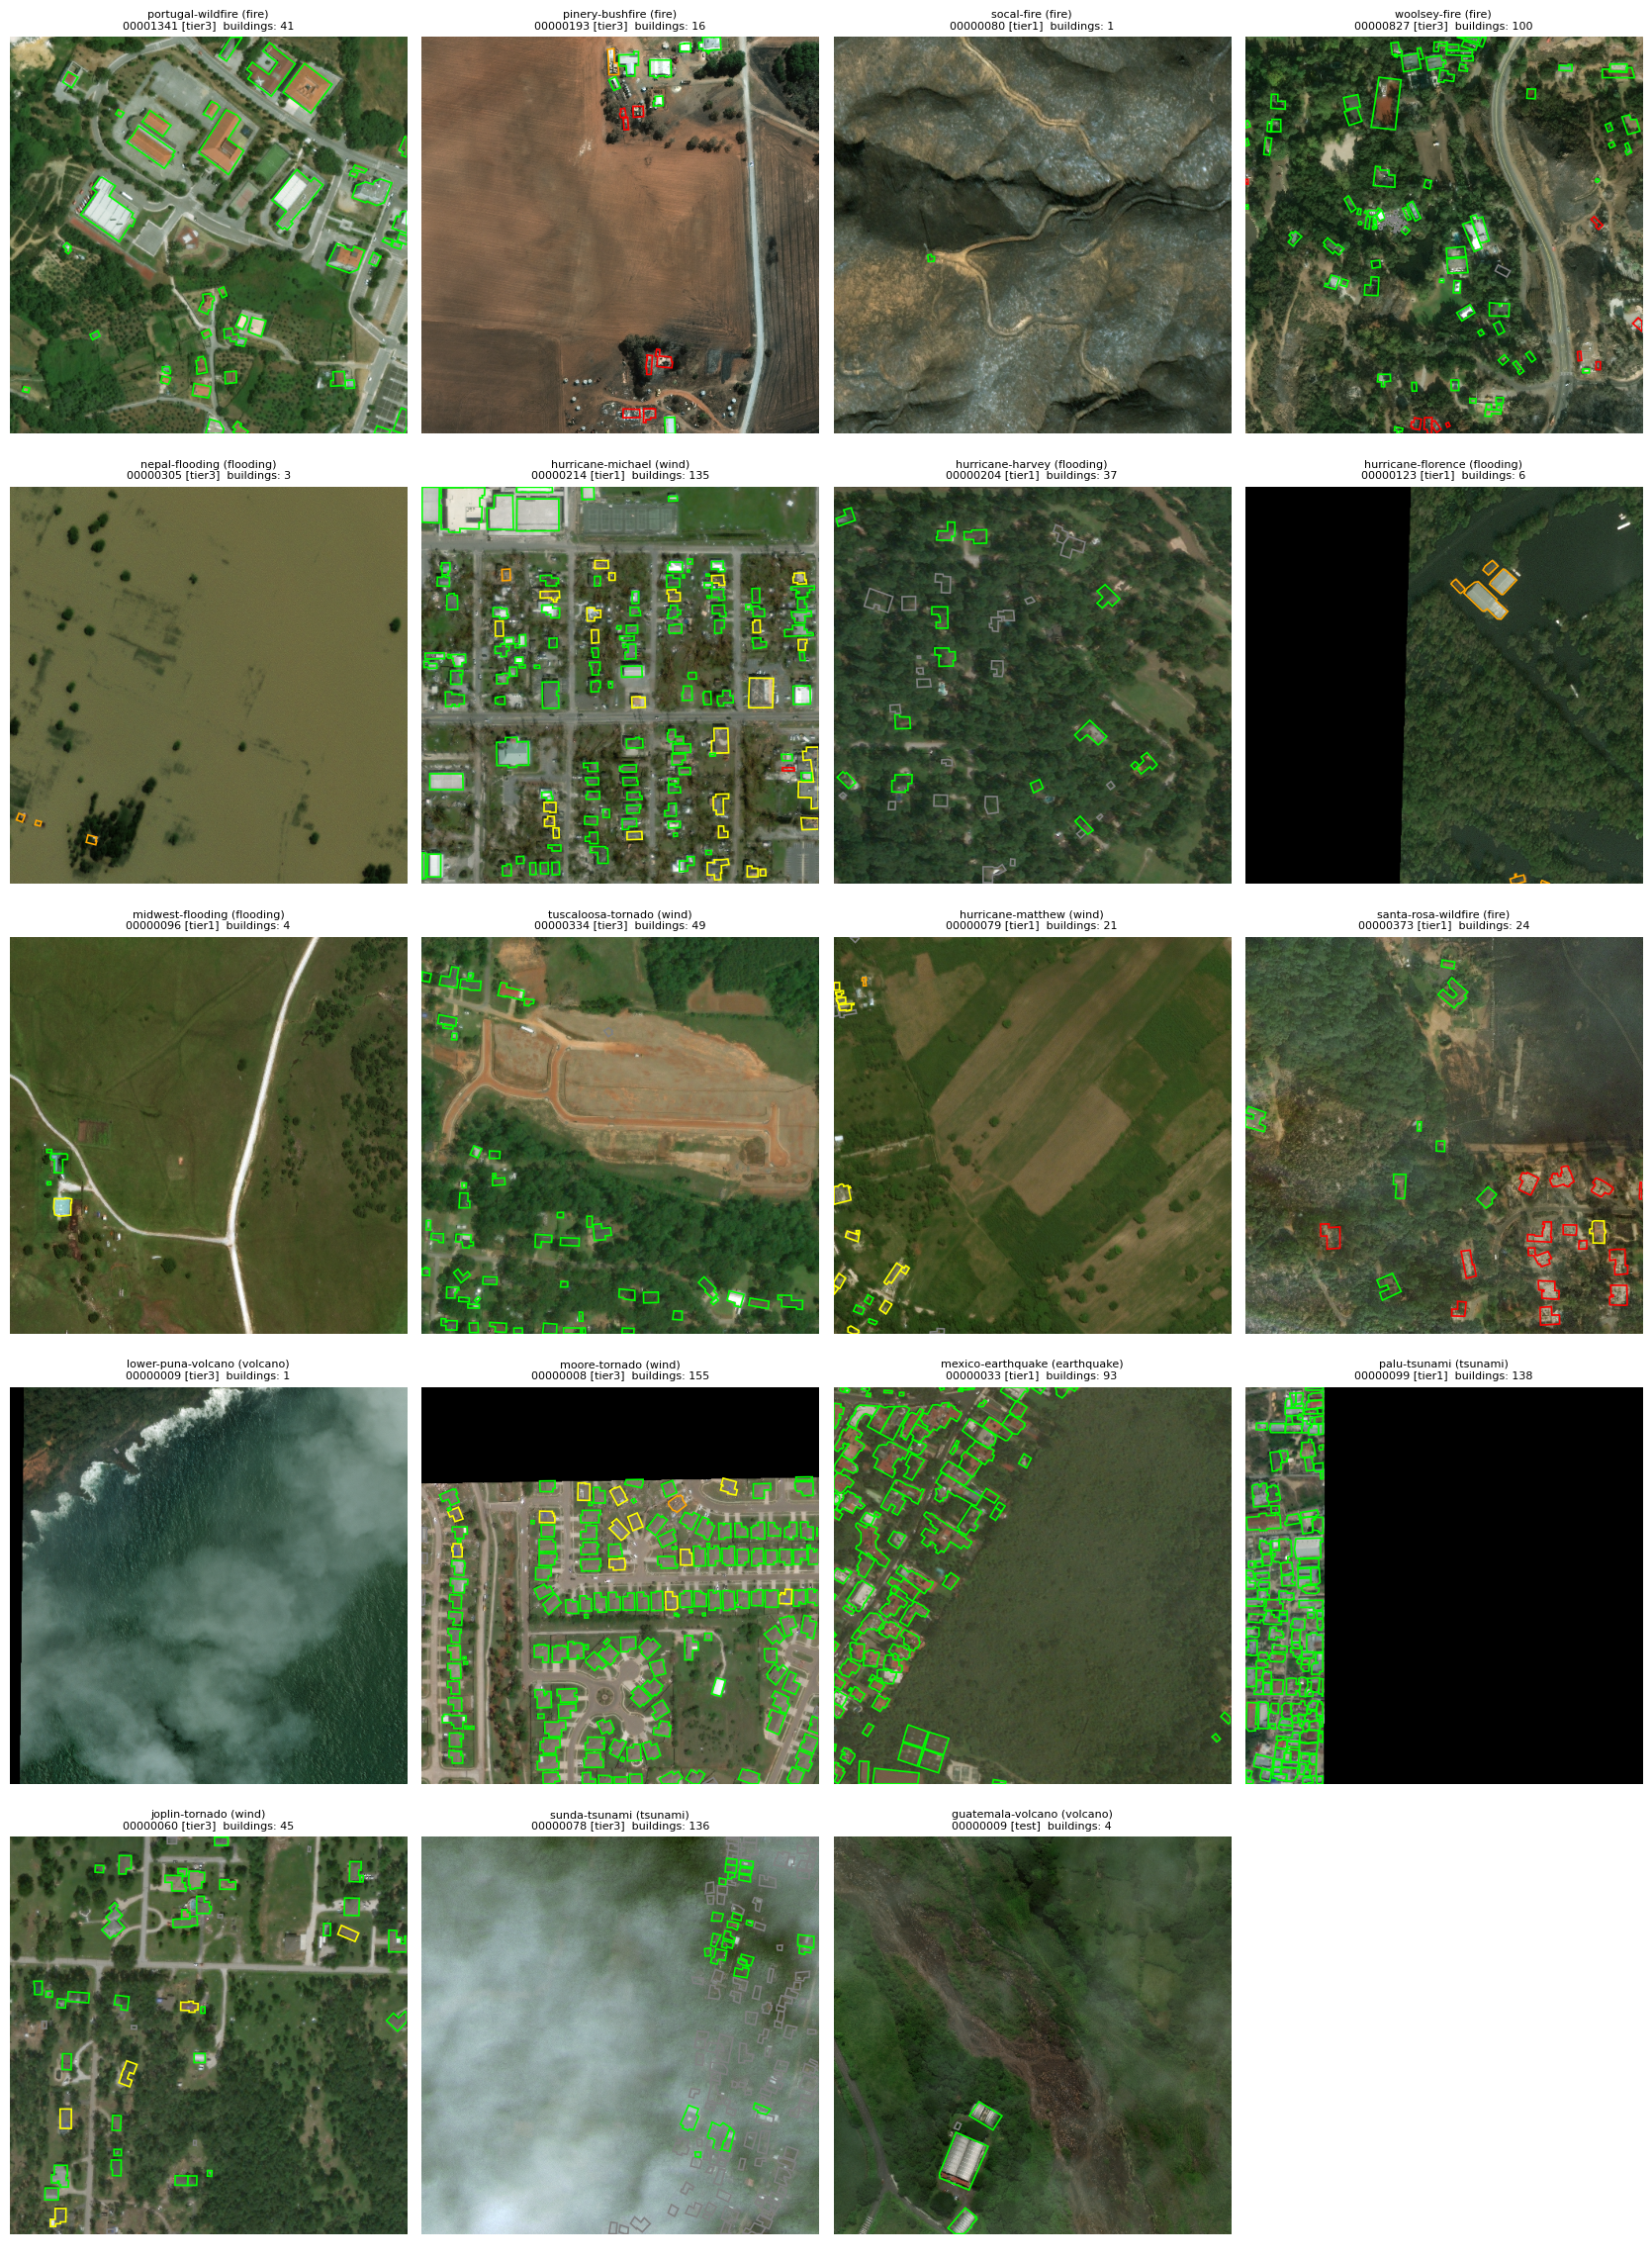

Outline colors: no-damage = lime, minor-damage = yellow, major-damage = orange, destroyed = red, un-classified = gray


In [25]:
def tif_path(split, image_id, when):
    return DATA_ROOT / split / "images" / f"{image_id}_{when}_disaster.tif"


def load_rgb(path, max_size=512):
    """Read a GeoTIFF (reduced to max_size pixels) as an (H, W, 3) uint8 array. Also returns the scale used."""
    with rasterio.open(path) as src:
        scale = min(1.0, max_size / max(src.width, src.height))
        out_h, out_w = max(1, int(src.height * scale)), max(1, int(src.width * scale))
        arr = src.read([1, 2, 3], out_shape=(3, out_h, out_w))
    arr = np.transpose(arr, (1, 2, 0))
    if arr.dtype != np.uint8:                     # stretch to 0-255 only if not 8-bit
        arr = arr.astype(np.float32)
        arr = (255 * (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)).astype(np.uint8)
    return arr, scale


def draw_outlines(ax, image_id, split, scale):
    lab = read_json(DATA_ROOT / split / "labels" / f"{image_id}_post_disaster.json")
    found = Counter()
    for b in get_buildings(lab):
        pts = parse_wkt_xy(b["wkt"])
        if pts is None:
            continue
        sub = b["properties"].get("subtype", "(no subtype)")
        found[sub] += 1
        ax.add_patch(Polygon(pts * scale, closed=True, fill=False,
                             edgecolor=COLORS.get(sub, "cyan"), linewidth=1.2))
    return found


def show_event_samples(seed=SEED, ncols=4):
    rng = random.Random(seed)
    events = list(ev_meta.sort_values("images", ascending=False).index)
    nrows = int(np.ceil(len(events) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4.6 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, event in zip(axes, events):
        cand = img[(img["disaster"] == event) & img["has_post_tif"] & img["has_post_json"]]
        withb = cand[cand["n_buildings_post"] > 0]
        cand = withb if len(withb) else cand
        ax.axis("off")
        if cand.empty:
            ax.set_title(f"{event}\n(no image with label)", fontsize=8)
            continue
        row = cand.iloc[rng.randrange(len(cand))]
        arr, scale = load_rgb(tif_path(row["split"], row["image_id"], "post"))
        ax.imshow(arr)
        found = draw_outlines(ax, row["image_id"], row["split"], scale)
        ax.set_title(f"{event} ({row['disaster_type']})\n{row['image_id'].split('_')[-1]} [{row['split']}]  "
                     f"buildings: {sum(found.values())}", fontsize=8)
    for ax in axes[len(events):]:
        ax.axis("off")
    plt.tight_layout()
    save_fig("samples_per_event")
    plt.show()


show_event_samples()
legend_text = ", ".join(f"{c} = {COLORS.get(c, 'cyan')}" for c in CLASSES)
print("Outline colors:", legend_text)

## 10. Image colors per event (domain shift check)
We read a few images per event (reduced size) and compute the mean color. Each row shows the mean color of the **pre** and the **post** images of one event. If events have very different colors (vegetation, soil, water, season, sensor), a model trained on one event may not work well on another.

events:   0%|          | 0/19 [00:00<?, ?it/s]

,n_images,pre_R,pre_G,pre_B,post_R,post_G,post_B
disaster,,,,,,,
guatemala-volcano,15,50.1,69.8,40.3,54.4,72.3,44.2
hurricane-florence,15,49.0,66.0,38.7,42.2,60.2,33.9
hurricane-harvey,15,75.1,88.3,56.0,79.7,91.1,61.5
hurricane-matthew,15,84.2,97.2,65.4,72.7,87.1,54.6
hurricane-michael,15,73.7,81.7,62.4,81.2,88.9,68.3
joplin-tornado,15,88.8,94.4,74.2,85.3,89.4,68.9
lower-puna-volcano,15,60.6,76.8,56.9,66.9,82.9,62.0
mexico-earthquake,15,84.0,83.2,62.8,77.8,75.9,54.5
midwest-flooding,15,56.6,71.9,42.3,58.1,70.1,43.0


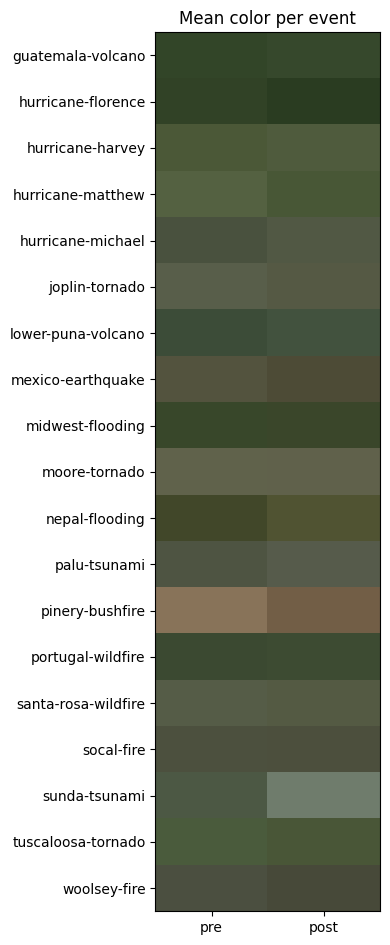

In [26]:
N_COLOR_SAMPLES = 15      # images per event (more = slower but more stable)


def mean_rgb(path, max_size=256):
    arr, _ = load_rgb(path, max_size)
    return arr.reshape(-1, 3).mean(axis=0)


rng = random.Random(SEED)
color_rows = []
for event in tqdm(list(ev_meta.index), desc="events"):
    cand = img[(img["disaster"] == event) & img["has_pre_tif"] & img["has_post_tif"]]
    if cand.empty:
        continue
    picks = cand.sample(n=min(N_COLOR_SAMPLES, len(cand)), random_state=SEED)
    pre = np.array([mean_rgb(tif_path(r.split, r.image_id, "pre")) for r in picks.itertuples()])
    post = np.array([mean_rgb(tif_path(r.split, r.image_id, "post")) for r in picks.itertuples()])
    color_rows.append({"disaster": event, "n_images": len(picks),
                       "pre_R": pre[:, 0].mean(), "pre_G": pre[:, 1].mean(), "pre_B": pre[:, 2].mean(),
                       "post_R": post[:, 0].mean(), "post_G": post[:, 1].mean(), "post_B": post[:, 2].mean()})

color_df = pd.DataFrame(color_rows).set_index("disaster").sort_index()
display(color_df.round(1))
color_df.to_csv(OUT_DIR / "event_mean_colors.csv")

sw = np.zeros((len(color_df), 2, 3))
sw[:, 0, :] = color_df[["pre_R", "pre_G", "pre_B"]].values / 255
sw[:, 1, :] = color_df[["post_R", "post_G", "post_B"]].values / 255
fig, ax = plt.subplots(figsize=(4, 0.45 * len(color_df) + 1))
ax.imshow(np.clip(sw, 0, 1), aspect="auto")
ax.set_xticks([0, 1])
ax.set_xticklabels(["pre", "post"])
ax.set_yticks(range(len(color_df)))
ax.set_yticklabels(color_df.index)
ax.set_title("Mean color per event")
plt.tight_layout()
save_fig("mean_color_per_event")
plt.show()

## 11. Event summary table (for the subset decision)
One row per event with the main numbers. This table is saved in `reports/eda/event_summary.csv`.

Columns: `no-damage` ... `un-classified` are building counts. `damaged %` = (minor + major + destroyed) / (all four damage classes). `smallest damage class` is the number of buildings in the rarest class among the three damage classes (a small number means that the event gives very few examples of that class).

In [27]:
summary = ev_meta[["disaster_type", "images", "sensors", "off_nadir_median", "sun_elevation_median"]].copy()
summary = summary.join(pv[AVAILABLE_SPLITS].add_prefix("images_"))
summary = summary.join(ct_event.rename(columns={"total": "buildings"}))
dmg = ["minor-damage", "major-damage", "destroyed"]
summary["damaged %"] = (100 * summary[dmg].sum(axis=1) / summary[DAMAGE4].sum(axis=1)).round(1)
summary["smallest damage class"] = summary[dmg].min(axis=1)
summary = summary.sort_values("buildings", ascending=False)
display(summary.round(2))
summary.to_csv(OUT_DIR / "event_summary.csv")

,disaster_type,images,sensors,off_nadir_median,sun_elevation_median,images_tier1,images_tier3,images_test,no-damage,minor-damage,major-damage,destroyed,un-classified,buildings,damaged %,smallest damage class
disaster,,,,,,,,,,,,,,,,
palu-tsunami,tsunami,155,WORLDVIEW02,36.44,68.85,113,0,42,36382,1,821,6203,547,43954,16.2,1
mexico-earthquake,earthquake,159,WORLDVIEW02,34.38,68.67,121,0,38,43350,194,49,3,86,43682,0.6,3
nepal-flooding,flooding,619,GEOEYE01,34.13,66.97,0,619,0,31225,5134,4721,502,1683,43265,24.9,502
hurricane-harvey,flooding,427,GEOEYE01,42.91,66.45,319,0,108,15591,3534,10612,597,395,30729,48.6,597
hurricane-michael,wind,441,GEOEYE01,28.87,50.76,343,0,98,18235,6570,2311,940,287,28343,35.0,940
portugal-wildfire,fire,1869,WORLDVIEW02,25.35,71.46,0,1869,0,20787,176,296,1090,1064,23413,7.0,176
moore-tornado,wind,227,GEOEYE01,13.55,70.26,0,227,0,19453,886,449,1584,586,22958,13.0,449
hurricane-matthew,wind,311,"WORLDVIEW02, WORLDVIEW03_VNIR",29.84,63.01,238,0,73,3132,8887,2281,2826,1002,18128,81.7,2281
santa-rosa-wildfire,fire,300,GEOEYE01,21.35,43.56,226,0,74,12507,97,72,4435,65,17176,26.9,72


## 12. Subset planner
Choose the source events (training) and the target events (held out, unseen) and check what they contain. The proposal says to hold out **complete events** as target domains and avoid splitting the same event randomly.

Fill in the two lists below with event names from the tables above, then run the cell. The thresholds are only warnings and you can change them.

In [28]:
SOURCE_EVENTS = []      # example: ["event-a", "event-b"]
TARGET_EVENTS = []      # example: ["event-c"]
USE_SPLITS = AVAILABLE_SPLITS
MIN_PER_CLASS = 100     # warning if a class has fewer buildings than this (our own choice, not a rule)

all_events = sorted(ev_meta.index)
if not SOURCE_EVENTS or not TARGET_EVENTS:
    print("Fill SOURCE_EVENTS and TARGET_EVENTS. Events available:")
    print(all_events)
else:
    unknown = [e for e in SOURCE_EVENTS + TARGET_EVENTS if e not in all_events]
    assert not unknown, f"Unknown event names: {unknown}"

    def subset_counts(events):
        sub = bld[bld["disaster"].isin(events) & bld["split"].isin(USE_SPLITS)]
        n_img = int((img["disaster"].isin(events) & img["split"].isin(USE_SPLITS)).sum())
        return n_img, sub["subtype"].value_counts().reindex(CLASSES, fill_value=0)

    n_src, c_src = subset_counts(SOURCE_EVENTS)
    n_tgt, c_tgt = subset_counts(TARGET_EVENTS)
    plan = pd.DataFrame({"source": c_src, "target": c_tgt})
    plan["source %"] = (100 * plan["source"] / plan["source"].sum()).round(1)
    plan["target %"] = (100 * plan["target"] / plan["target"].sum()).round(1)
    display(plan)
    print(f"Source: {n_src:,} images, {int(c_src.sum()):,} buildings")
    print(f"Target: {n_tgt:,} images, {int(c_tgt.sum()):,} buildings")

    p_s = c_src[DAMAGE4] / max(c_src[DAMAGE4].sum(), 1)
    p_t = c_tgt[DAMAGE4] / max(c_tgt[DAMAGE4].sum(), 1)
    tvd = 0.5 * float(np.abs(p_s - p_t).sum())
    print(f"Difference between source and target class distributions: {tvd:.2f} (0 = same, 1 = completely different)")

    overlap = set(SOURCE_EVENTS) & set(TARGET_EVENTS)
    if overlap:
        print("WARNING: these events are in both source and target:", sorted(overlap))
    for name, counts in (("source", c_src), ("target", c_tgt)):
        low = [c for c in DAMAGE4 if counts[c] < MIN_PER_CLASS]
        if low:
            print(f"WARNING: {name} has fewer than {MIN_PER_CLASS} buildings in: {low}")

    types = img[img["disaster"].isin(SOURCE_EVENTS + TARGET_EVENTS)].drop_duplicates("disaster")
    display(types.assign(role=lambda d: np.where(d["disaster"].isin(TARGET_EVENTS), "target", "source"))
            [["disaster", "disaster_type", "role", "sensor"]].set_index("disaster"))
    plan.to_csv(OUT_DIR / "subset_plan.csv")

Fill SOURCE_EVENTS and TARGET_EVENTS. Events available:
['guatemala-volcano', 'hurricane-florence', 'hurricane-harvey', 'hurricane-matthew', 'hurricane-michael', 'joplin-tornado', 'lower-puna-volcano', 'mexico-earthquake', 'midwest-flooding', 'moore-tornado', 'nepal-flooding', 'palu-tsunami', 'pinery-bushfire', 'portugal-wildfire', 'santa-rosa-wildfire', 'socal-fire', 'sunda-tsunami', 'tuscaloosa-tornado', 'woolsey-fire']


## 13. Notes for the team (fill in after discussion)
- Events and disaster types we have:
- Class balance (which classes are rare, which events have enough damaged buildings):
- Differences between events (sensor, angle, colors, dates):
- Problems found (images with no buildings, missing files, un-classified buildings, clouds):
- Proposed source events:
- Proposed target event(s):
- How many images/buildings we will upload to Drive: